# Lab 9
- **Student Name**: Daniel Alejandro Castillo Martin
- **Student ID**: N10019284
- **Course:** Advanced Deep Learning - AIGC-5500-0NA
- **Professor**: Hossein Pourmodheji
---

## Lab Overview

This lab implements and verifies reinforcement learning agents on CartPole. It compares full DQN, DQN without a target network, DQN with a recent-transition window, DQN with a smaller replay buffer, REINFORCE, and PPO. Each configuration runs for 20,000 environment steps across seeds 0, 1, and 2. The experiments compare learning curves, final returns, and steps to reach a smoothed return of 150.

## 1. Imports and Setup

### 1.1 Imports and Configuration

In [1]:
# Import the required libraries
from IPython.display import Image, display
from pathlib import Path
from copy import deepcopy
from time import perf_counter
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F

# Import custom modules
from scripts import lab09_starter as S
from src.dqn import dqn_target, huber_loss, train_dqn
from src.policy_gradient import ppo_clipped_objective, returns_to_go

# Print the PyTorch version
print(f'PyTorch version: {torch.__version__}')

PyTorch version: 2.15.0+cpu


In [2]:
# Set the seed for reproducibility
EXPERIMENT_SEEDS = (0, 1, 2)
STEP_BUDGET = S.BUDGET
RETURN_THRESHOLD = 150

# Set the output directory
OUTPUT_DIR = Path('output')
OUTPUT_DIR.mkdir(exist_ok = True)

## 2. Losses

### 2.1 DQN Target and Huber Loss

In [3]:
# Give all three cases the same reward and next-state action values
cases = ('True termination', 'Ordinary transition', 'Time-limit truncation')
rewards = torch.ones(3)
next_q_values = torch.tensor([[4.0, 7.0]] * 3, requires_grad = True)

# Mark the time-limit case as truncated so it still bootstraps
terminated = torch.tensor([True, False, False])
truncated = torch.tensor([False, False, True])
expected_targets = torch.tensor([1.0, 7.3, 7.3])

targets = dqn_target(rewards, next_q_values, terminated, gamma = 0.9)

# Compare each computed target with its hand-calculated value
for case, term, trunc, actual, expected in zip(cases, terminated, truncated, targets, expected_targets):
    status = 'PASS' if torch.isclose(actual, expected).item() else 'FAIL'
    print(f'{case} (terminated = {term.item()}, truncated = {trunc.item()}) | target = {actual.item():.2f} | expected = {expected.item():.2f} | {status}')

True termination (terminated = True, truncated = False) | target = 1.00 | expected = 1.00 | PASS
Ordinary transition (terminated = False, truncated = False) | target = 7.30 | expected = 7.30 | PASS
Time-limit truncation (terminated = False, truncated = True) | target = 7.30 | expected = 7.30 | PASS


In [4]:
# Verify that the targets are detached from the computation graph.
status = 'PASS' if not targets.requires_grad else 'FAIL'
print(f'Target requires gradients: {targets.requires_grad} | {status}')

Target requires gradients: False | PASS


In [5]:
# Test one error in the quadratic region and two in the linear region
errors = torch.tensor([0.5, 3.0, -3.0])
zero_targets = torch.zeros_like(errors)

losses = huber_loss(errors, zero_targets)

# Compare each loss with the hand calculation and PyTorch's implementation
expected_losses = torch.tensor([0.125, 2.5, 2.5])
pytorch_losses = F.huber_loss(errors, zero_targets, reduction = 'none')
matches = torch.isclose(losses, expected_losses) & torch.isclose(losses, pytorch_losses)

for error, actual, expected, reference, match in zip(errors, losses, expected_losses, pytorch_losses, matches):
    status = 'PASS' if match.item() else 'FAIL'
    print(f'Error {error.item():+.1f} | Huber = {actual.item():.3f} | expected = {expected.item():.3f} | PyTorch = {reference.item():.3f} | {status}')

Error +0.5 | Huber = 0.125 | expected = 0.125 | PyTorch = 0.125 | PASS
Error +3.0 | Huber = 2.500 | expected = 2.500 | PyTorch = 2.500 | PASS
Error -3.0 | Huber = 2.500 | expected = 2.500 | PyTorch = 2.500 | PASS


### 2.2 DQN Fixed-Point Check

This experiment uses one state and one action. Each transition gives a reward of 1 and returns to the same state. With a discount factor of 0.9, the Bellman equation is \(Q = 1 + 0.9Q\), so the exact value is \(Q = 10\).

Both runs use the same initial weights and 3,000 Adam updates. The first refreshes a separate target network every 50 updates. The second uses the current online network to compute the bootstrap target.

In [6]:
# Define fixed point check function
def run_fixed_point_check(use_target_network):
    # Use the same initial weights for both runs.
    S.set_seed(0)
    online_network = S.QNet(obs_dim = 1, n_actions = 1)
    target_network = deepcopy(online_network) if use_target_network else online_network
    optimizer = torch.optim.Adam(online_network.parameters(), lr = 0.01)

    # Represent the single transition from the state back to itself.
    state = torch.zeros((1, 1))
    reward = torch.ones(1)
    terminated = torch.zeros(1, dtype = torch.bool)

    for update in range(1, 3001):
        # Compute the bootstrap target without tracking gradients.
        with torch.no_grad():
            next_q_values = target_network(state)
            target = dqn_target(reward, next_q_values, terminated, gamma = 0.9)

        # Update the online network using the Huber loss.
        prediction = online_network(state).squeeze(dim = 1)
        loss = huber_loss(prediction, target).mean()

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # Refresh the separate target network every 50 updates.
        if use_target_network and update % 50 == 0:
            target_network.load_state_dict(online_network.state_dict())

    # Read the final estimate from the trained online network.
    with torch.no_grad():
        return online_network(state).item()

In [7]:
# Compare both final estimates with the exact Bellman fixed point
exact_value = 10.0

for label, use_target_network in (('With target network', True), ('Without target network', False)):
    learned_value = run_fixed_point_check(use_target_network)
    absolute_error = abs(learned_value - exact_value)

    print(f'{label} | learned Q = {learned_value:.6f} | exact Q = {exact_value:.2f} | absolute error = {absolute_error:.6f}')

With target network | learned Q = 9.980935 | exact Q = 10.00 | absolute error = 0.019065
Without target network | learned Q = 9.999994 | exact Q = 10.00 | absolute error = 0.000006


After 3,000 updates, the network with a separate target estimated Q = 9.980935, and the network using its own predictions as targets estimated Q = 9.999994. The second run finished closer to 10 in this one-state experiment. The CartPole ablation will test how removing the target network affects learning across many states and actions.

In [8]:
# Check both sides of the clipping interval with positive and negative advantages
ratios = torch.tensor([1.3, 1.3, 0.7, 0.7])
advantages = torch.tensor([1.0, -1.0, 1.0, -1.0])
expected_objectives = torch.tensor([1.2, -1.3, 0.7, -0.8])

objectives = ppo_clipped_objective(ratios, advantages, clip = 0.2)

# Compare each result with the hand-calculated objective.
for ratio, advantage, actual, expected in zip(ratios, advantages, objectives, expected_objectives):
    status = 'PASS' if torch.isclose(actual, expected).item() else 'FAIL'
    print(f'Ratio = {ratio.item():.1f} | advantage = {advantage.item():+.1f} | objective = {actual.item():+.2f} | expected = {expected.item():+.2f} | {status}')

Ratio = 1.3 | advantage = +1.0 | objective = +1.20 | expected = +1.20 | PASS
Ratio = 1.3 | advantage = -1.0 | objective = -1.30 | expected = -1.30 | PASS
Ratio = 0.7 | advantage = +1.0 | objective = +0.70 | expected = +0.70 | PASS
Ratio = 0.7 | advantage = -1.0 | objective = -0.80 | expected = -0.80 | PASS


In [9]:
# Check the discounted return at each step of a three-reward sequence.
rewards = [1.0, 1.0, 1.0]
expected_returns = torch.tensor([1.75, 1.50, 1.00])
actual_returns = torch.tensor(returns_to_go(rewards, gamma = 0.5))

# Compare the full sequence with the hand-calculated values.
status = 'PASS' if torch.allclose(actual_returns, expected_returns) else 'FAIL'
print(f'Returns = {actual_returns.tolist()} | expected = {expected_returns.tolist()} | {status}')

Returns = [1.75, 1.5, 1.0] | expected = [1.75, 1.5, 1.0] | PASS


With a clip of 0.2, the clipped ratios lie between 0.8 and 1.2. The objective takes the smaller of the two products for each sample. With a positive advantage, a ratio of 1.3 gives min(1.3, 1.2) = 1.2. With a negative advantage, a ratio of 0.7 gives min(-0.7, -0.8) = -0.8.

The returns to go for rewards [1, 1, 1] at a discount of 0.5 are [1.75, 1.50, 1.00]. The first return includes all three rewards, and the last return includes only the final reward.

## 3. DQN Baseline

### 3.1 Training and Per-Seed Results

Train the full DQN with seeds 0, 1, and 2. Final return is the mean return of episodes that ended during the final 2,000 environment steps. Steps to 150 is the first 500-step checkpoint where the smoothed return reaches 150.

In [10]:
baseline_runs = {}
baseline_curves = {}

for seed in EXPERIMENT_SEEDS:
    print(f'Training full DQN with seed {seed}...', flush = True)

    # Train for the full environment-step budget and record the elapsed time.
    start = perf_counter()
    episodes, q_measurements = train_dqn(seed = seed, steps = STEP_BUDGET)
    elapsed = perf_counter() - start

    # Use the starter helpers to compute the learning curve and summary metrics.
    curve = S.smooth_curve(episodes, steps = STEP_BUDGET)
    final_return = S.final_return(episodes, steps = STEP_BUDGET)
    steps_to_threshold = S.steps_to_reach(curve, RETURN_THRESHOLD)

    # Keep each seed's results for the plots and later ablation comparisons.
    baseline_curves[seed] = curve
    baseline_runs[seed] = {
        'final_return': final_return,
        'steps_to_150': steps_to_threshold,
        'q_measurements': q_measurements,
        'seconds': elapsed
        }

    threshold_label = 'Never reached' if steps_to_threshold is None else str(steps_to_threshold)
    print(f'Seed {seed} | final return = {final_return:.2f} | steps to 150 = {threshold_label} | training time = {elapsed:.1f} s')

Training full DQN with seed 0...
Seed 0 | final return = 118.35 | steps to 150 = 8000 | training time = 54.7 s
Training full DQN with seed 1...
Seed 1 | final return = 52.15 | steps to 150 = Never reached | training time = 48.5 s
Training full DQN with seed 2...
Seed 2 | final return = 45.32 | steps to 150 = 11500 | training time = 49.3 s


### 3.2 Learning Curves

The figure shows a separate learning curve for each seed and the mean across seeds in bold. Returns are averaged over a trailing window of 2,000 environment steps and plotted every 500 steps.

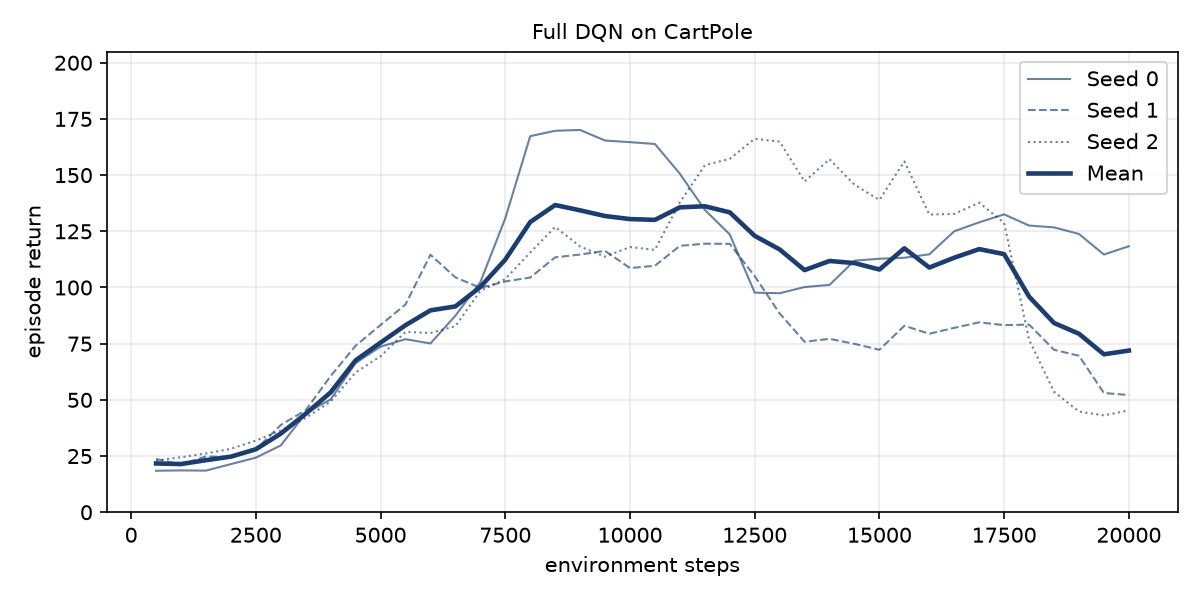

In [12]:
# Plot the three seed curves and their mean using the starter helper.
fig, ax = plt.subplots(figsize = (8, 4))
S.plot_curves(ax, baseline_curves, 'Full DQN on CartPole', steps = STEP_BUDGET)

# Give each seed a distinct line style and label the mean.
for line, seed, style in zip(ax.lines, EXPERIMENT_SEEDS, ('-', '--', ':')):
    line.set_label(f'Seed {seed}')
    line.set_linestyle(style)
    line.set_alpha(0.65)

ax.lines[-1].set_label('Mean')
ax.legend()
fig.tight_layout()

# Save the figure and display it in the notebook.
figure_path = OUTPUT_DIR / 'dqn_baseline_curves.png'
fig.savefig(figure_path, dpi = 150)
plt.close(fig)
Image(filename = str(figure_path))

Across the three seeds, the full DQN had a mean final return of 71.94, with individual results ranging from 45.32 to 118.35. Seed 0 first reached a smoothed return of 150 at step 8,000, and seed 2 reached it at step 11,500. Seed 1 never reached 150.

All three seeds finished below 150. Seed 2 reached the threshold during training and ended with the lowest final return (45.32), showing why both metrics matter: one captures when performance first reaches the threshold, and the other captures performance near the end of training.

## 4. DQN Ablations

### 4.1 Per-Seed Results

The three configurations remove the separate target network, replace replay with chronological batches of 64, or reduce the replay capacity to 1,000. Each configuration runs for 20,000 environment steps with seeds 0, 1, and 2. Final return and steps to 150 use the same smoothing as the baseline.

The no-replay configuration starts updating after the first 64 transitions and uses each full batch once. This gives it 312 optimizer updates, compared with 19,500 in the replay configurations. That difference matters when interpreting the results.

In [13]:
ablation_settings = {
    'No target network': {'use_target_network': False},
    'No replay': {'use_replay': False},
    'Replay capacity 1,000': {'replay_capacity': 1_000}
    }

ablation_runs = {}
ablation_curves = {}

for name, settings in ablation_settings.items():
    ablation_runs[name] = {}
    ablation_curves[name] = {}

    for seed in EXPERIMENT_SEEDS:
        print(f'Training {name}, seed {seed}...', flush = True)

        # Train under the same seed and environment-step budget as the baseline.
        start = perf_counter()
        episodes, q_measurements = train_dqn(seed = seed, steps = STEP_BUDGET, **settings)
        elapsed = perf_counter() - start

        # Apply the same starter metrics and retain the probe measurements.
        curve = S.smooth_curve(episodes, steps = STEP_BUDGET)
        final_return = S.final_return(episodes, steps = STEP_BUDGET)
        steps_to_threshold = S.steps_to_reach(curve, RETURN_THRESHOLD)
        peak_abs_q = max(max_abs_q for _, _, max_abs_q in q_measurements)

        ablation_curves[name][seed] = curve
        ablation_runs[name][seed] = {
            'final_return': final_return,
            'steps_to_150': steps_to_threshold,
            'q_measurements': q_measurements,
            'seconds': elapsed
            }

        threshold = 'Never reached' if steps_to_threshold is None else str(steps_to_threshold)
        print(f'{name} | seed={seed} | final return={final_return:.2f} | steps to 150={threshold} | peak |Q|={peak_abs_q:.2f} | training time={elapsed:.1f} s')

Training No target network, seed 0...
No target network | seed=0 | final return=9.61 | steps to 150=Never reached | peak |Q|=82017736.00 | training time=46.1 s
Training No target network, seed 1...
No target network | seed=1 | final return=9.53 | steps to 150=Never reached | peak |Q|=73508128.00 | training time=51.0 s
Training No target network, seed 2...
No target network | seed=2 | final return=9.61 | steps to 150=Never reached | peak |Q|=86605336.00 | training time=62.5 s
Training No replay, seed 0...
No replay | seed=0 | final return=9.61 | steps to 150=Never reached | peak |Q|=534.93 | training time=3.0 s
Training No replay, seed 1...
No replay | seed=1 | final return=9.53 | steps to 150=Never reached | peak |Q|=465.40 | training time=2.8 s
Training No replay, seed 2...
No replay | seed=2 | final return=9.57 | steps to 150=Never reached | peak |Q|=399.63 | training time=3.0 s
Training Replay capacity 1,000, seed 0...
Replay capacity 1,000 | seed=0 | final return=150.54 | steps to 

### 4.2 Q-Value Measurements

Every 1,000 environment steps, the online network is evaluated on the same 500 probe states. The figure shows the mean across probe states of the highest action value in each state. The table below the figure reports the largest absolute action value observed at any probe checkpoint for each seed.

With a reward of 1 per step and a discount factor of 0.99, the discounted return is bounded above by 100. The dashed line marks this reference.

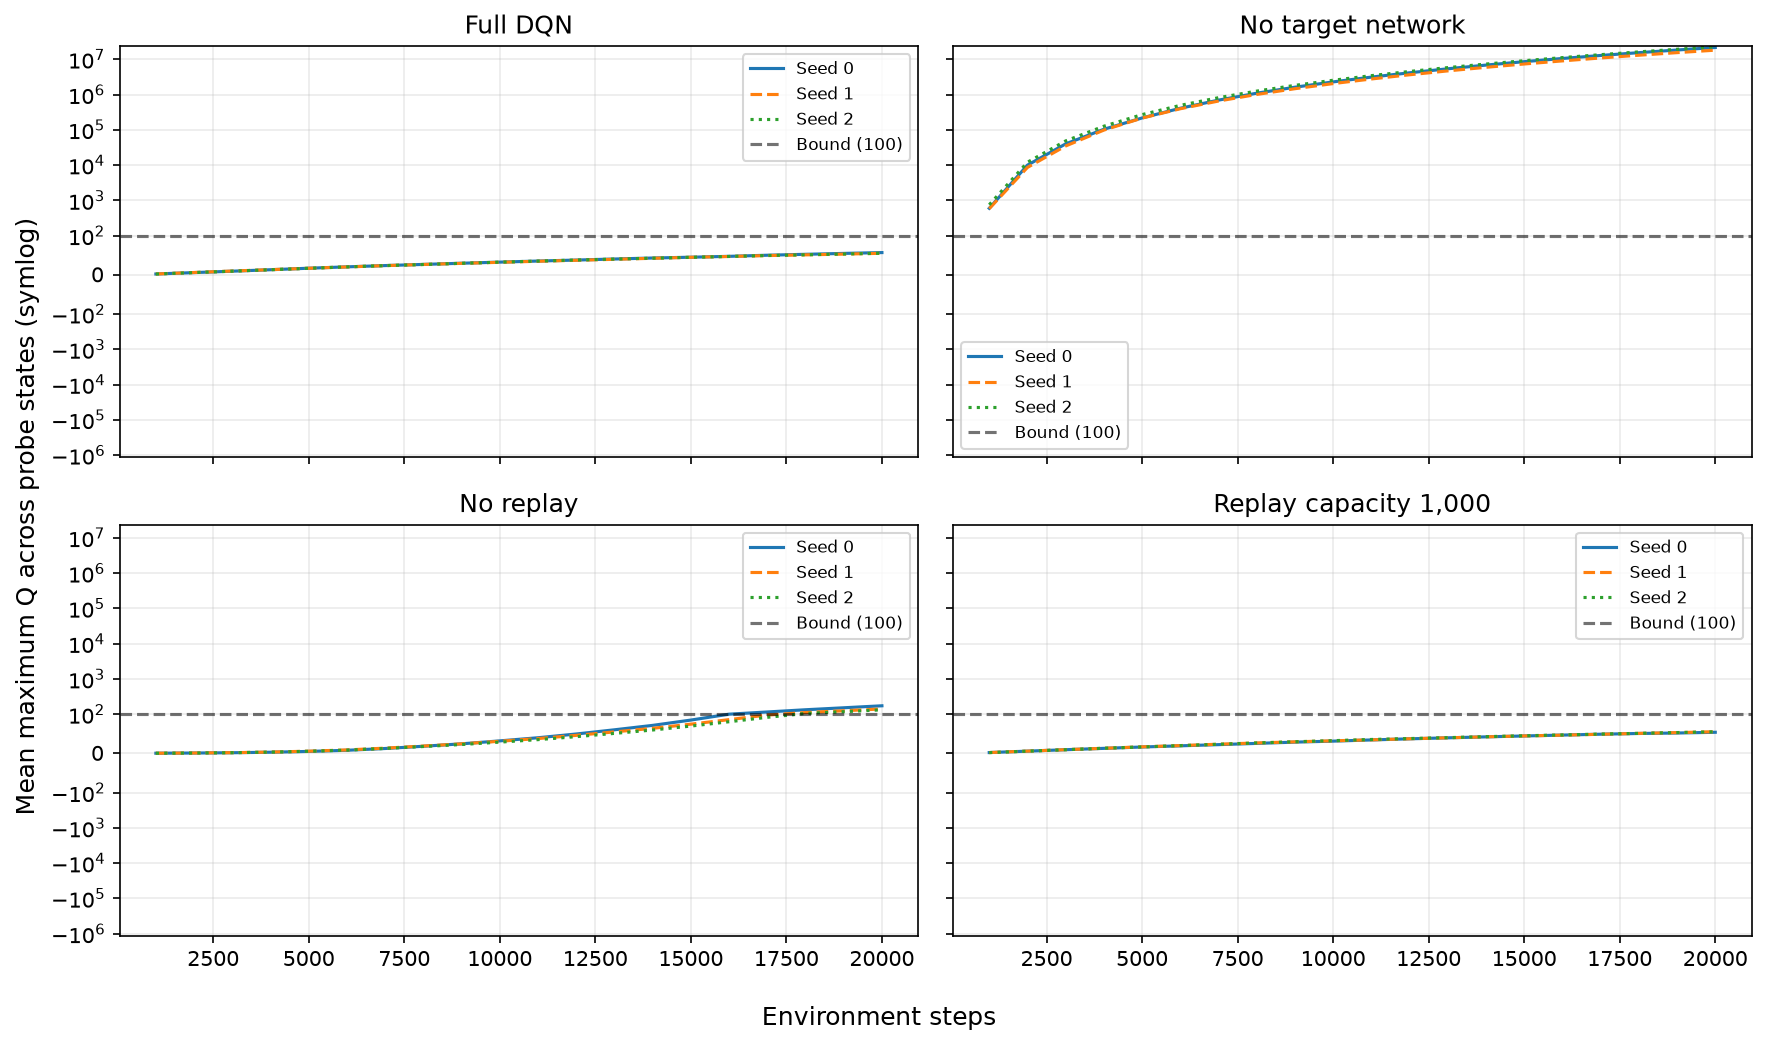

In [15]:
# Include the full DQN as a reference for all three ablations.
dqn_runs = {'Full DQN': baseline_runs, **ablation_runs}
seed_styles = ('-', '--', ':')

fig, axes = plt.subplots(2, 2, figsize = (12, 7), sharex = True, sharey = True)

for ax, (name, runs) in zip(axes.flat, dqn_runs.items()):
    # Plot the mean of the best action values for each seed.
    for seed, style in zip(EXPERIMENT_SEEDS, seed_styles):
        steps, mean_max_q, _ = zip(*runs[seed]['q_measurements'])
        ax.plot(steps, mean_max_q, linestyle = style, label = f'Seed {seed}')

    ax.axhline(100, color = 'black', linestyle = '--', alpha = 0.55, label = 'Bound (100)')
    ax.set_title(name)
    ax.grid(alpha = 0.25)
    ax.legend(fontsize = 8)

# Keep values near the bound readable if an ablation produces much larger estimates.
axes[0, 0].set_yscale('symlog', linthresh = 100)
fig.supxlabel('Environment steps')
fig.supylabel('Mean maximum Q across probe states (symlog)')
fig.tight_layout()

figure_path = OUTPUT_DIR / 'dqn_ablation_q_values.png'
fig.savefig(figure_path, dpi = 150, bbox_inches = 'tight')
plt.close(fig)
Image(filename = str(figure_path))

Removing the target network reduced mean final return from 71.94 to 9.58, a drop of 62.36 points, larger than predicted. None of the three seeds reached 150, and peak absolute Q ranged from 73.5 to 86.6 million, far above the bound of 100.

Removing replay also produced a mean final return near 10 (9.57), and no seed reached 150. Peak absolute Q ranged from 399.63 to 534.93, exceeding 100 on every seed but staying far below the peaks without a target network. This configuration used chronological batches once each and performed 312 optimizer updates versus 19,500 with replay. The experiment cannot determine how much of the performance drop came from correlated batches, lack of reuse, or fewer updates.

The 1,000-transition buffer reached 150 on all three seeds and achieved a mean final return of 129.28, 57.34 points above the baseline and more than predicted. Its peak absolute Q stayed below 57 on every seed. The final-return range of 117.88–150.54 overlaps the baseline range of 45.32–118.35, so this comparison does not meet the predefined non-overlap rule. The smaller buffer retained both uniform sampling and transition reuse, so this result speaks to replay history length.